# Adult Census Income — exploração inicial

**Fonte:** [Kaggle · uciml/adult-census-income](https://www.kaggle.com/datasets/uciml/adult-census-income/data) · [UCI Machine Learning Repository (id 2)](https://archive.ics.uci.edu/dataset/2/adult)

## Sobre o dataset

O **Adult Census Income** (também chamado *Adult* ou *Census Income*) foi extraído do banco de dados do **Censo dos Estados Unidos de 1994** (*Current Population Survey*) por Ronny Kohavi e Barry Becker, da equipe de *Data Mining and Visualization* da Silicon Graphics, e doado ao repositório UCI em 1996. Os registros foram filtrados para manter apenas linhas "razoavelmente limpas": idade acima de 16 anos, renda bruta ajustada acima de 100, peso amostral acima de 1 e mais de zero horas trabalhadas por semana (`AAGE>16 && AGI>100 && AFNLWGT>1 && HRSWK>0`).

A **tarefa** associada é de **classificação binária**: prever se a renda anual de uma pessoa é superior a US$ 50 mil (`>50K`) ou não (`<=50K`) a partir de 14 atributos demográficos e ocupacionais. É um dos datasets mais usados como *benchmark* em aprendizado de máquina e, por conter sexo e raça, também em estudos de justiça algorítmica (*fairness*).

A versão usada aqui é o arquivo `adult.csv` do Kaggle, que corresponde à **partição de treino** do UCI (`adult.data`): **32.561 registros × 15 colunas** (14 atributos + alvo). O UCI completo soma 48.842 registros (treino + teste). Nesta versão os valores ausentes aparecem como `?` (nas colunas `workclass`, `occupation` e `native.country`) e os nomes das colunas usam ponto (`education.num`) em vez de hífen.

**Sobre `fnlwgt` (*final weight*):** é o peso amostral calculado pelo Census Bureau, controlado por estimativas independentes da população civil não institucionalizada dos EUA (por estado, origem hispânica, raça, idade e sexo). Indica quantas pessoas da população cada linha representa. Pessoas com características demográficas semelhantes tendem a ter pesos semelhantes, mas essa afirmação só vale dentro de um mesmo estado. Não é uma característica da pessoa e, por isso, costuma ser descartado na modelagem.

**Particularidades que valem registrar:**

- `education.num` é um *ranking* ordinal de `education` (1 = pré-escola … 16 = doutorado), **não** "anos de estudo".
- Em `native.country`, `Columbia` é grafia incorreta de *Colombia*; `South` e `Hong` estão truncados (provavelmente Coreia do Sul e Hong Kong).
- `capital.gain` e `capital.loss` são zero para a grande maioria das pessoas.
- Licença CC BY 4.0. Citação: Becker, B. & Kohavi, R. (1996). *Adult* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5XW20

## Objetivo deste notebook

Primeira exploração dos dados: dicionário de dados, tradução dos termos para português (módulo [`traducao.py`](traducao.py), reutilizável em outros notebooks), valores ausentes, **classes distintas por atributo** e **distribuição das classes de cada coluna**. Cada gráfico vem acompanhado da tabela que o originou.

## 1. Configuração

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

from traducao import (
    traduzir, traduzir_dataframe, dicionario_dados, rotulo, ordem_classes,
    COLUNAS, TIPOS, AUSENTE_PT,
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 80)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 160)

# Estilo dos gráficos: um só tom para categorias nominais, grade discreta, sem bordas.
AZUL = "#2a78d6"
CINZA_OUTROS = "#c3c2b7"
TEXTO = "#0b0b0b"
TEXTO_SEC = "#52514e"
GRADE = "#e6e5e2"

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.edgecolor": GRADE,
    "axes.linewidth": 1,
    "axes.grid": True,
    "grid.color": GRADE,
    "grid.linewidth": 1,
    "grid.linestyle": "-",
    "axes.axisbelow": True,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlepad": 12,
    "axes.labelsize": 10,
    "axes.labelcolor": TEXTO_SEC,
    "xtick.color": TEXTO_SEC,
    "ytick.color": TEXTO_SEC,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "text.color": TEXTO,
    "legend.frameon": False,
})

In [2]:
CAMINHO = "adult.csv"
df_original = pd.read_csv(CAMINHO)

print(f"{df_original.shape[0]:,} linhas × {df_original.shape[1]} colunas".replace(",", "."))
df_original.head()

32.561 linhas × 15 colunas


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


## 2. Dicionário de dados e tradução

A função `dicionario_dados()` do módulo `traducao` descreve cada coluna: nome original, identificador em português (sem acentos, para usar em código), rótulo legível, tipo e descrição.

In [3]:
dicionario = dicionario_dados()
dicionario

,Coluna original,Coluna (pt),Rótulo,Tipo,Nº de classes,Descrição
0,age,idade,Idade,numérica,<NA>,"Idade da pessoa, em anos."
1,workclass,classe_trabalho,Classe de trabalho,categórica,8,"Tipo de vínculo/empregador: setor privado, governo (federal, estadual, local), autônomo etc."
2,fnlwgt,peso_amostral,Peso amostral,numérica,<NA>,Peso amostral (final weight) atribuído pelo Census Bureau: quantas pessoas da população a linha representa. Não descreve a pessoa.
3,education,escolaridade,Escolaridade,categórica (ordinal),16,Maior nível de escolaridade concluído.
4,education.num,escolaridade_num,Escolaridade (nível numérico),numérica (ordinal),<NA>,Codificação ordinal da escolaridade (1 = pré-escola ... 16 = doutorado). Não representa anos de estudo.
5,marital.status,estado_civil,Estado civil,categórica,7,Estado civil.
6,occupation,ocupacao,Ocupação,categórica,14,Grupo ocupacional (categorias amplas do censo).
7,relationship,relacao_familiar,Relação familiar,categórica,6,"Relação da pessoa com o responsável pelo domicílio (marido, esposa, filho(a) etc.)."
8,race,raca,Raça,categórica,5,Raça declarada (categorias do censo dos EUA).
9,sex,sexo,Sexo,categórica (binária),2,Sexo.


`traduzir_dataframe` renomeia as colunas e traduz os valores categóricos. Por padrão o marcador `?` vira `Não informado`; use `ausente=None` para mantê-lo ou `ausente=float("nan")` para convertê-lo em `NaN` (útil na etapa de modelagem).

In [4]:
df = traduzir_dataframe(df_original)
df.head()

,idade,classe_trabalho,peso_amostral,escolaridade,escolaridade_num,estado_civil,ocupacao,relacao_familiar,raca,sexo,ganho_capital,perda_capital,horas_semana,pais_origem,renda
0,90,Não informado,77053,Ensino médio completo,9,Viúvo(a),Não informado,Sem vínculo familiar,Branca,Feminino,0,4356,40,Estados Unidos,≤ 50 mil
1,82,Setor privado,132870,Ensino médio completo,9,Viúvo(a),Executivo/gerencial,Sem vínculo familiar,Branca,Feminino,0,4356,18,Estados Unidos,≤ 50 mil
2,66,Não informado,186061,Superior incompleto,10,Viúvo(a),Não informado,Não casado(a),Negra,Feminino,0,4356,40,Estados Unidos,≤ 50 mil
3,54,Setor privado,140359,7ª a 8ª série,4,Divorciado(a),Operação de máquinas/inspeção,Não casado(a),Branca,Feminino,0,3900,40,Estados Unidos,≤ 50 mil
4,41,Setor privado,264663,Superior incompleto,10,Separado(a),Profissional especializado,Filho(a),Branca,Feminino,0,3900,40,Estados Unidos,≤ 50 mil


In [5]:
# A função `traduzir` também traduz termos isolados, o que é útil em outros notebooks e scripts.
exemplos = [("workclass", None), ("Self-emp-inc", "workclass"), ("Prof-specialty", None),
            ("marital-status", None), ("?", None), (">50K", "income")]
for termo, coluna in exemplos:
    print(f"{termo!r:>20}  ->  {traduzir(termo, coluna)!r}")

         'workclass'  ->  'classe_trabalho'
      'Self-emp-inc'  ->  'Autônomo (incorporado)'
    'Prof-specialty'  ->  'Profissional especializado'
    'marital-status'  ->  'estado_civil'
                 '?'  ->  'Não informado'
              '>50K'  ->  '> 50 mil'


## 3. Funções auxiliares

Duas funções padronizam a exploração: `distribuicao_categorica` (barras horizontais + tabela de contagem e percentual) e `distribuicao_numerica` (histograma + resumo estatístico + tabela por faixa). Todas as categorias de uma coluna são nominais e recebem **uma única cor**; quando há muitas classes, a cauda é agrupada em "Outros" apenas no gráfico, e a tabela mostra todas.

In [6]:
def formatar_int(n):
    return f"{int(n):,}".replace(",", ".")


def formatar_pct(p):
    if 0 < p < 0.05:
        return "<0,1%"
    return f"{p:.1f}%".replace(".", ",")


def n_distintos(serie):
    """Número de valores distintos, sem contar o marcador de ausente."""
    return serie[serie != AUSENTE_PT].nunique()


def classes_ordenadas(serie):
    """Classes da mais frequente para a menos frequente, sem o marcador de ausente."""
    return [c for c in serie.value_counts().index if c != AUSENTE_PT]


def eixo_compacto(ax, eixo="x"):
    fmt = FuncFormatter(lambda v, _: (f"{v / 1000:g}K" if v >= 1000 else f"{v:g}").replace(".", ","))
    (ax.xaxis if eixo == "x" else ax.yaxis).set_major_formatter(fmt)


def tabela_frequencia(serie, ordem=None):
    """Contagem e percentual de cada classe, por frequência ou na ordem informada.

    Classes presentes nos dados mas ausentes de `ordem` (ex.: 'Não informado') vão para o fim,
    para que nenhuma linha seja descartada e os percentuais continuem somando 100%."""
    contagem = serie.value_counts(dropna=False)
    if ordem is not None:
        presentes = [c for c in ordem if c in contagem.index]
        restantes = [c for c in contagem.index if c not in presentes]
        contagem = contagem.reindex(presentes + restantes)
    tabela = pd.DataFrame({
        "Contagem": contagem,
        "Percentual (%)": (contagem / contagem.sum() * 100).round(2),
    })
    tabela.index.name = "Classe"
    return tabela


def grafico_barras(contagem, titulo, max_classes=20, rotular=True, xlabel="Contagem", total=None):
    """Barras horizontais em um só tom. Acima de `max_classes`, a cauda vira 'Outros' (só no gráfico).

    `total` é o denominador dos percentuais nos rótulos (padrão: soma das barras)."""
    contagem = contagem.copy()
    cores = [AZUL] * len(contagem)
    if max_classes is not None and len(contagem) > max_classes:
        # agrupa as classes MENOS frequentes, seja qual for a ordem das barras
        principais = contagem.nlargest(max_classes).index
        cauda = contagem.drop(principais)
        contagem = pd.concat([
            contagem[contagem.index.isin(principais)],
            pd.Series({f"Outros ({len(cauda)} classes)": cauda.sum()}),
        ])
        cores = [AZUL] * max_classes + [CINZA_OUTROS]

    total = total if total is not None else contagem.sum()
    posicoes = np.arange(len(contagem))[::-1]
    altura = max(2.4, 0.42 * len(contagem) + 1.2)

    fig, ax = plt.subplots(figsize=(9, altura))
    ax.barh(posicoes, contagem.values, color=cores, height=0.62)
    ax.set_yticks(posicoes, [str(c) for c in contagem.index])
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="y", visible=False)
    if rotular:
        for pos, valor in zip(posicoes, contagem.values):
            ax.text(valor + contagem.max() * 0.012, pos,
                    f"{formatar_int(valor)}  ({formatar_pct(valor / total * 100)})",
                    va="center", fontsize=8.5, color=TEXTO_SEC)
    ax.set_xlim(0, contagem.max() * 1.24)
    eixo_compacto(ax, "x")
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    plt.tight_layout()
    plt.show()


def distribuicao_categorica(df, coluna, ordem=None, max_classes=20, titulo=None):
    """Gráfico de barras + tabela (contagem e %) da distribuição das classes de uma coluna."""
    tabela = tabela_frequencia(df[coluna], ordem=ordem)
    titulo = titulo or f"{rotulo(coluna)}: distribuição das classes (n = {formatar_int(len(df))})"
    grafico_barras(tabela["Contagem"], titulo, max_classes=max_classes)
    display(tabela)
    return tabela


def distribuicao_numerica(df, coluna, bins=20, titulo=None, somente_positivos=False):
    """Histograma + resumo estatístico + tabela de contagem por faixa de uma coluna numérica.

    A tabela usa exatamente as barras do histograma: faixas [a, b), fechadas à esquerda
    e abertas à direita; apenas a última faixa inclui o limite superior."""
    serie = df[coluna]
    if somente_positivos:
        serie = serie[serie > 0]

    nome = rotulo(coluna) + (" (apenas valores > 0)" if somente_positivos else "")
    resumo = serie.describe().rename({
        "count": "n", "mean": "média", "std": "desvio padrão", "min": "mínimo",
        "25%": "Q1 (25%)", "50%": "mediana", "75%": "Q3 (75%)", "max": "máximo",
    }).to_frame(nome).T

    # As faixas da tabela são as mesmas barras do histograma (np.histogram):
    # fechadas à esquerda e abertas à direita, [a, b); só a última inclui o limite superior.
    contagens, bordas = np.histogram(serie, bins=bins)
    faixas = [f"[{formatar_int(a)}, {formatar_int(b)})" for a, b in zip(bordas[:-1], bordas[1:])]
    faixas[-1] = faixas[-1][:-1] + "]"
    tabela = pd.DataFrame({
        "Contagem": contagens,
        "Percentual (%)": (contagens / contagens.sum() * 100).round(2),
    }, index=pd.Index(faixas, name="Faixa"))

    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.bar(bordas[:-1], contagens, width=np.diff(bordas), align="edge",
           color=AZUL, edgecolor="white", linewidth=1.5)
    ax.grid(axis="x", visible=False)
    ax.set_title(titulo or f"{rotulo(coluna)}: distribuição (n = {formatar_int(len(serie))})")
    ax.set_xlabel(rotulo(coluna))
    ax.set_ylabel("Contagem")
    eixo_compacto(ax, "x")
    eixo_compacto(ax, "y")
    plt.tight_layout()
    plt.show()

    display(resumo)
    display(tabela)
    return tabela

## 4. Visão geral

Tipos de dados, número de valores distintos por coluna e valores ausentes. O marcador `Não informado` **não** é contado como valor distinto; ele aparece na coluna de ausentes.

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   idade             32561 non-null  int64
 1   classe_trabalho   32561 non-null  str  
 2   peso_amostral     32561 non-null  int64
 3   escolaridade      32561 non-null  str  
 4   escolaridade_num  32561 non-null  int64
 5   estado_civil      32561 non-null  str  
 6   ocupacao          32561 non-null  str  
 7   relacao_familiar  32561 non-null  str  
 8   raca              32561 non-null  str  
 9   sexo              32561 non-null  str  
 10  ganho_capital     32561 non-null  int64
 11  perda_capital     32561 non-null  int64
 12  horas_semana      32561 non-null  int64
 13  pais_origem       32561 non-null  str  
 14  renda             32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


In [8]:
visao_geral = pd.DataFrame({
    "Tipo (pandas)": df.dtypes.astype(str).values,
    "Tipo (semântico)": [TIPOS[en] for en in COLUNAS],
    "Valores distintos (sem ausentes)": [n_distintos(df[c]) for c in df.columns],
    "Ausentes ('?')": (df == AUSENTE_PT).sum().values,
}, index=pd.Index(df.columns, name="Coluna"))
visao_geral

,Tipo (pandas),Tipo (semântico),Valores distintos (sem ausentes),Ausentes ('?')
Coluna,,,,
idade,int64,numérica,73,0
classe_trabalho,str,categórica,8,1836
peso_amostral,int64,numérica,21648,0
escolaridade,str,categórica (ordinal),16,0
escolaridade_num,int64,numérica (ordinal),16,0
estado_civil,str,categórica,7,0
ocupacao,str,categórica,14,1843
relacao_familiar,str,categórica,6,0
raca,str,categórica,5,0


### Valores ausentes

No CSV original os ausentes aparecem como `?`; após a tradução, como `Não informado`. Só três colunas têm ausentes.

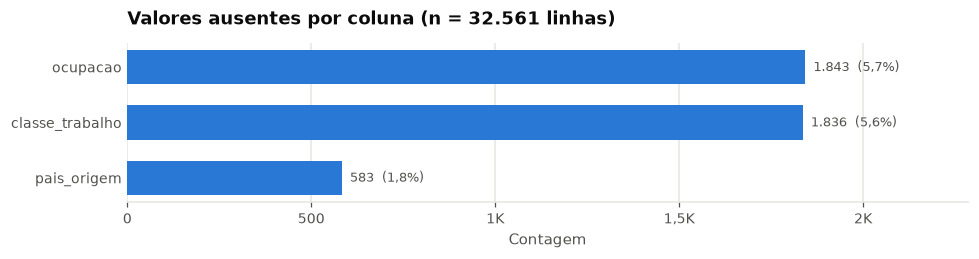

,Ausentes,Percentual (%)
Coluna,,
ocupacao,1843,5.66
classe_trabalho,1836,5.64
pais_origem,583,1.79


Linhas sem classe de trabalho E sem ocupação: 1.836
Linhas em que só a ocupação está ausente: 7 -> classe de trabalho delas: {'Nunca trabalhou': 7}
Linhas duplicadas (todas as colunas iguais): 24
Linhas com pelo menos um ausente: 2.399 (7,4%)


In [9]:
ausentes = (df == AUSENTE_PT).sum()
tab_ausentes = pd.DataFrame({
    "Ausentes": ausentes,
    "Percentual (%)": (ausentes / len(df) * 100).round(2),
})
tab_ausentes.index.name = "Coluna"
tab_ausentes = tab_ausentes[tab_ausentes["Ausentes"] > 0].sort_values("Ausentes", ascending=False)

grafico_barras(tab_ausentes["Ausentes"], f"Valores ausentes por coluna (n = {formatar_int(len(df))} linhas)",
               total=len(df))
display(tab_ausentes)

ambos = ((df["classe_trabalho"] == AUSENTE_PT) & (df["ocupacao"] == AUSENTE_PT)).sum()
linhas_com_ausente = (df == AUSENTE_PT).any(axis=1).sum()
so_ocupacao = df.loc[(df["ocupacao"] == AUSENTE_PT) & (df["classe_trabalho"] != AUSENTE_PT), "classe_trabalho"]
print(f"Linhas sem classe de trabalho E sem ocupação: {formatar_int(ambos)}")
print(f"Linhas em que só a ocupação está ausente: {formatar_int(len(so_ocupacao))} "
      f"-> classe de trabalho delas: {so_ocupacao.value_counts().to_dict()}")
print(f"Linhas duplicadas (todas as colunas iguais): {formatar_int(df.duplicated().sum())}")
print(f"Linhas com pelo menos um ausente: {formatar_int(linhas_com_ausente)} "
      f"({formatar_pct(linhas_com_ausente / len(df) * 100)})")

## 5. Classes distintas por atributo

Quantas classes cada atributo tem e quais são. O marcador `Não informado` não conta como classe (os ausentes estão na seção 4); nos gráficos de distribuição da seção 6 ele aparece como uma barra, para mostrar o peso dos ausentes em cada coluna. O gráfico cobre os atributos categóricos e ordinais; os numéricos contínuos (idade, peso amostral, ganho/perda de capital, horas por semana) aparecem na tabela, já que o peso amostral sozinho tem mais de 21 mil valores distintos e esconderia os demais.

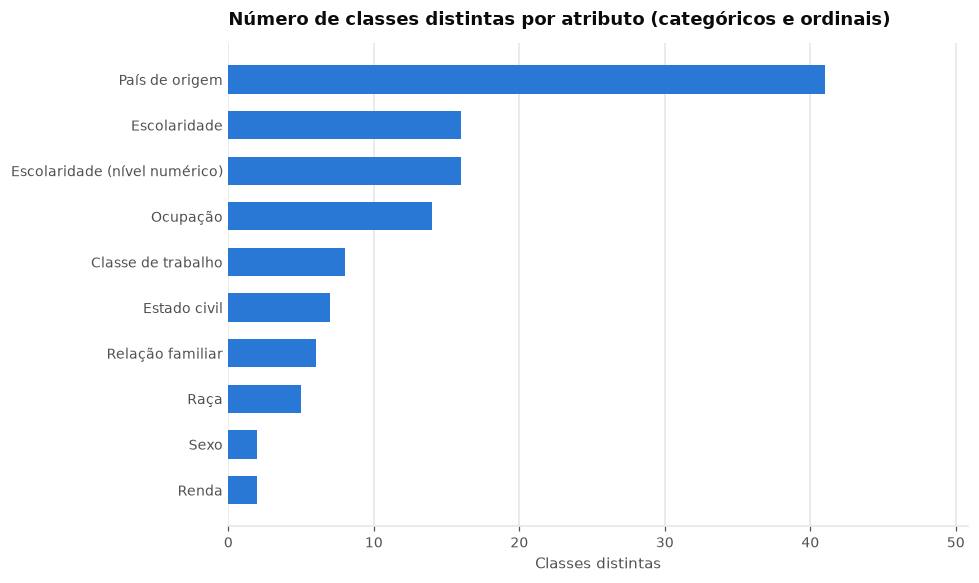

,Tipo,Classes distintas,Classes mais frequentes (até 6)
Atributo,,,
idade,numérica,73,"36, 31, 34, 23, 35, 33 …"
classe_trabalho,categórica,8,"Setor privado, Autônomo (não incorporado), Governo local, Governo estadual, Autônomo (incorporado), Governo federal …"
peso_amostral,numérica,21648,"123011, 164190, 203488, 148995, 126675, 121124 …"
escolaridade,categórica (ordinal),16,"Ensino médio completo, Superior incompleto, Bacharelado, Mestrado, Grau associado (vocacional), 11ª série …"
escolaridade_num,numérica (ordinal),16,"9, 10, 13, 14, 11, 7 …"
estado_civil,categórica,7,"Casado(a) – cônjuge civil, Solteiro(a), Divorciado(a), Separado(a), Viúvo(a), Casado(a) – cônjuge ausente …"
ocupacao,categórica,14,"Profissional especializado, Ofícios e reparos, Executivo/gerencial, Administrativo, Vendas, Outros serviços …"
relacao_familiar,categórica,6,"Marido, Sem vínculo familiar, Filho(a), Não casado(a), Esposa, Outro parente"
raca,categórica,5,"Branca, Negra, Asiática/Ilhas do Pacífico, Indígena americana/Esquimó, Outra"


In [10]:
categoricas = [COLUNAS[en] for en, tipo in TIPOS.items() if tipo.startswith(("categórica", "alvo"))]
ordinais = ["escolaridade_num"]
numericas = [c for c in df.columns if c not in categoricas and c not in ordinais]

resumo_classes = pd.DataFrame({
    "Tipo": [TIPOS[en] for en in COLUNAS],
    "Classes distintas": [n_distintos(df[COLUNAS[en]]) for en in COLUNAS],
    "Classes mais frequentes (até 6)": [
        ", ".join(map(str, classes_ordenadas(df[COLUNAS[en]])[:6]))
        + (" …" if n_distintos(df[COLUNAS[en]]) > 6 else "")
        for en in COLUNAS
    ],
}, index=pd.Index(df.columns, name="Atributo"))

n_classes = resumo_classes.loc[categoricas + ordinais, "Classes distintas"].sort_values(ascending=False)
n_classes.index = [rotulo(c) for c in n_classes.index]
grafico_barras(n_classes, "Número de classes distintas por atributo (categóricos e ordinais)",
               max_classes=None, rotular=False, xlabel="Classes distintas")
resumo_classes

### Lista completa das classes de cada atributo categórico

In [11]:
lista_classes = pd.DataFrame({
    "Nº de classes": [n_distintos(df[c]) for c in categoricas],
    "Classes (da mais frequente para a menos frequente)": [
        " | ".join(map(str, classes_ordenadas(df[c]))) for c in categoricas
    ],
}, index=pd.Index([f"{rotulo(c)} ({c})" for c in categoricas], name="Atributo"))
lista_classes

,Nº de classes,Classes (da mais frequente para a menos frequente)
Atributo,,
Classe de trabalho (classe_trabalho),8,Setor privado | Autônomo (não incorporado) | Governo local | Governo estadual | Autônomo (incorporado) | Governo federal | Sem remuneração | Nunca trabalhou
Escolaridade (escolaridade),16,Ensino médio completo | Superior incompleto | Bacharelado | Mestrado | Grau associado (vocacional) | 11ª série | Grau associado (acadêmico) | 10ª série | 7ª a 8ª série | Escola profissional | 9ª série | 12ª série | Doutorado | 5ª a 6ª série | 1ª a 4ª série | Pré-escola
Estado civil (estado_civil),7,Casado(a) – cônjuge civil | Solteiro(a) | Divorciado(a) | Separado(a) | Viúvo(a) | Casado(a) – cônjuge ausente | Casado(a) – cônjuge nas Forças Armadas
Ocupação (ocupacao),14,Profissional especializado | Ofícios e reparos | Executivo/gerencial | Administrativo | Vendas | Outros serviços | Operação de máquinas/inspeção | Transporte e movimentação | Carga e limpeza | Agricultura e pesca | Suporte técnico | Serviços de proteção | Serviço doméstico | Forças Armadas
Relação familiar (relacao_familiar),6,Marido | Sem vínculo familiar | Filho(a) | Não casado(a) | Esposa | Outro parente
Raça (raca),5,Branca | Negra | Asiática/Ilhas do Pacífico | Indígena americana/Esquimó | Outra
Sexo (sexo),2,Masculino | Feminino
País de origem (pais_origem),41,"Estados Unidos | México | Filipinas | Alemanha | Canadá | Porto Rico | El Salvador | Índia | Cuba | Inglaterra | Jamaica | Sul (não especificado) | China | Itália | República Dominicana | Vietnã | Guatemala | Japão | Polônia | Colômbia | Taiwan | Haiti | Irã | Portugal | Nicarágua | Peru | Grécia | França | Equador | Irlanda | Hong Kong | Trinidad e Tobago | Camboja | Laos | Tailândia | Iugoslávia | Territórios dos EUA (Guam, Ilhas Virgens etc.) | Honduras | Hungria | Escócia | Holanda"
Renda (renda),2,≤ 50 mil | > 50 mil


## 6. Distribuição das classes por coluna

Para cada coluna categórica: gráfico de barras (ordenado por frequência, ou na ordem natural quando a coluna é ordinal) e a tabela correspondente com contagem e percentual.

### 6.1 Variável alvo: renda

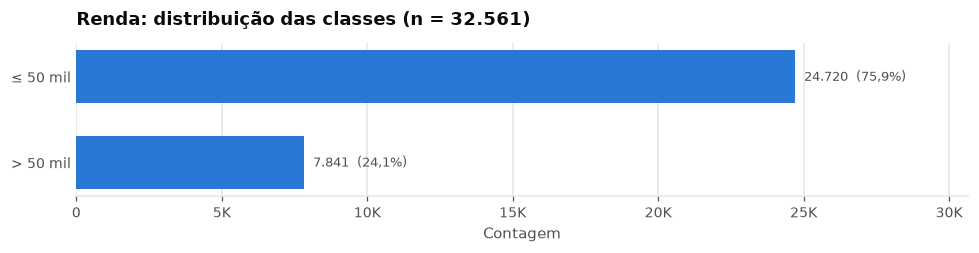

,Contagem,Percentual (%)
Classe,,
≤ 50 mil,24720,75.92
> 50 mil,7841,24.08


In [12]:
tab_renda = distribuicao_categorica(df, "renda", ordem=ordem_classes("renda"))

### 6.2 Sexo e raça

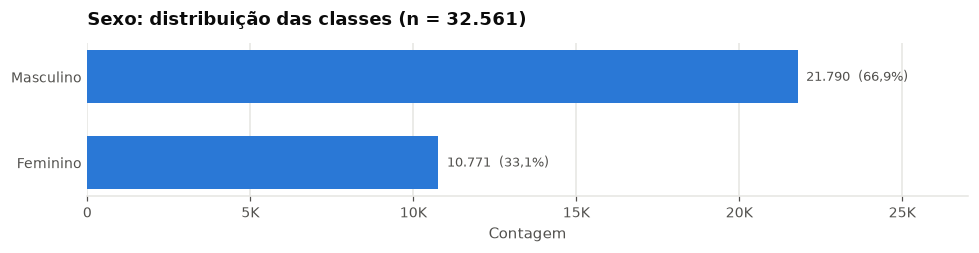

,Contagem,Percentual (%)
Classe,,
Masculino,21790,66.92
Feminino,10771,33.08


In [13]:
tab_sexo = distribuicao_categorica(df, "sexo")

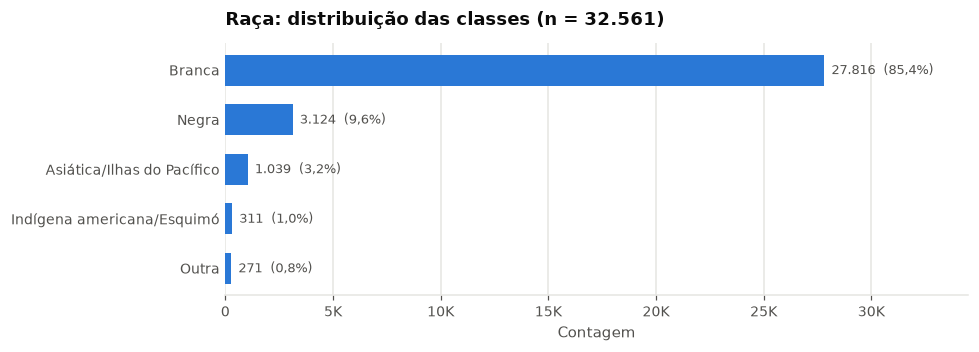

,Contagem,Percentual (%)
Classe,,
Branca,27816,85.43
Negra,3124,9.59
Asiática/Ilhas do Pacífico,1039,3.19
Indígena americana/Esquimó,311,0.96
Outra,271,0.83


In [14]:
tab_raca = distribuicao_categorica(df, "raca")

### 6.3 Classe de trabalho

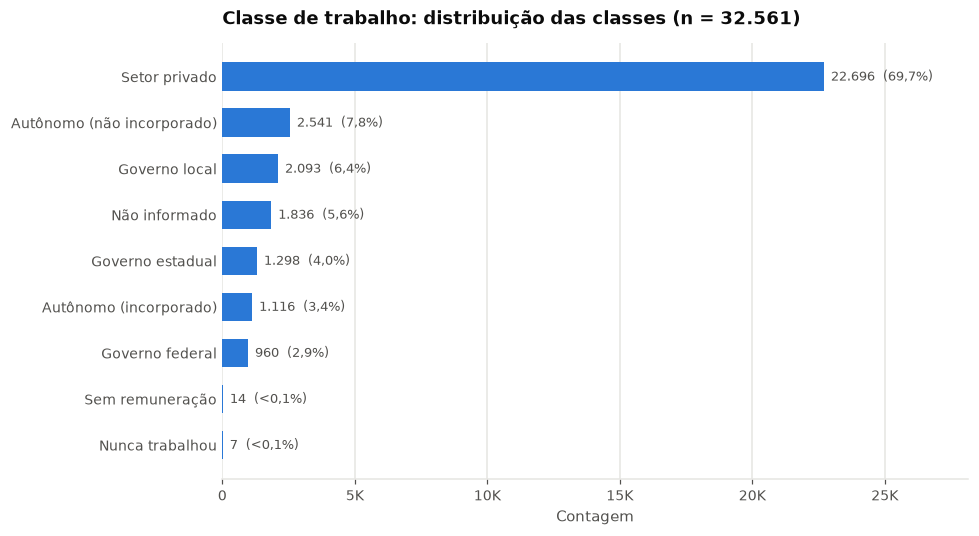

,Contagem,Percentual (%)
Classe,,
Setor privado,22696,69.70
Autônomo (não incorporado),2541,7.80
Governo local,2093,6.43
Não informado,1836,5.64
Governo estadual,1298,3.99
Autônomo (incorporado),1116,3.43
Governo federal,960,2.95
Sem remuneração,14,0.04
Nunca trabalhou,7,0.02


In [15]:
tab_classe_trabalho = distribuicao_categorica(df, "classe_trabalho")

### 6.4 Escolaridade

`escolaridade` é mostrada na **ordem natural** dos níveis (da pré-escola ao doutorado), que é exatamente a ordem codificada em `escolaridade_num`. A tabela de correspondência confirma o mapeamento 1:1 entre as duas colunas.

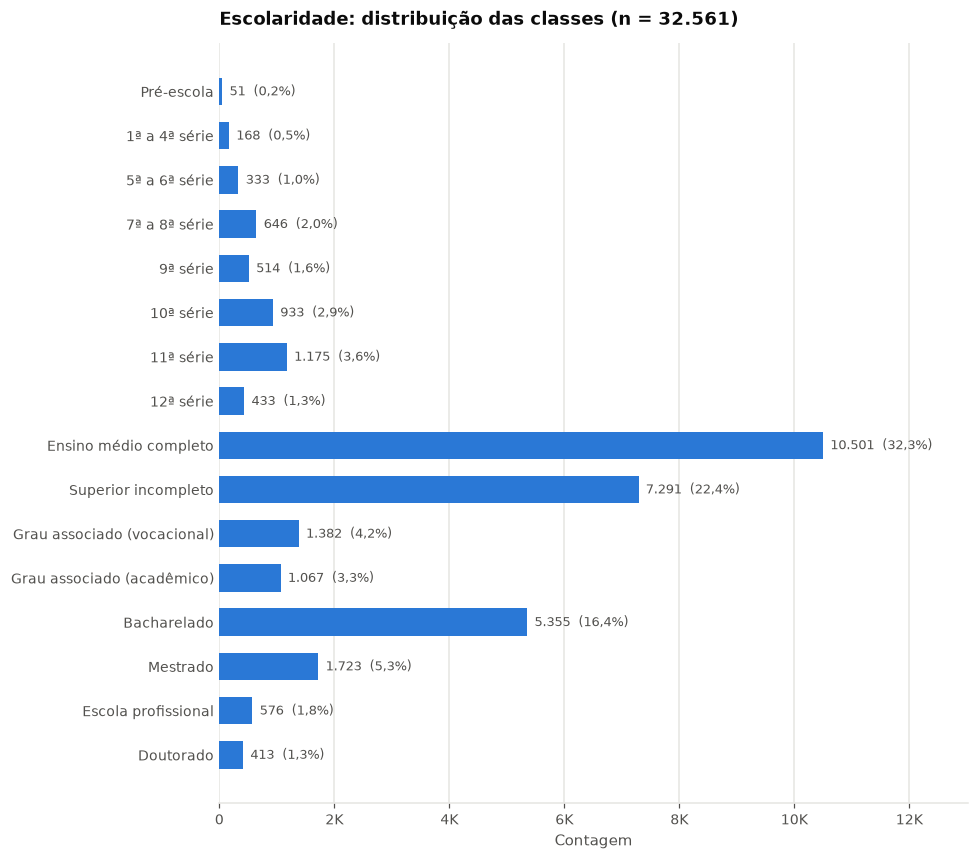

,Contagem,Percentual (%)
Classe,,
Pré-escola,51,0.16
1ª a 4ª série,168,0.52
5ª a 6ª série,333,1.02
7ª a 8ª série,646,1.98
9ª série,514,1.58
10ª série,933,2.87
11ª série,1175,3.61
12ª série,433,1.33
Ensino médio completo,10501,32.25


In [16]:
tab_escolaridade = distribuicao_categorica(df, "escolaridade", ordem=ordem_classes("escolaridade"))

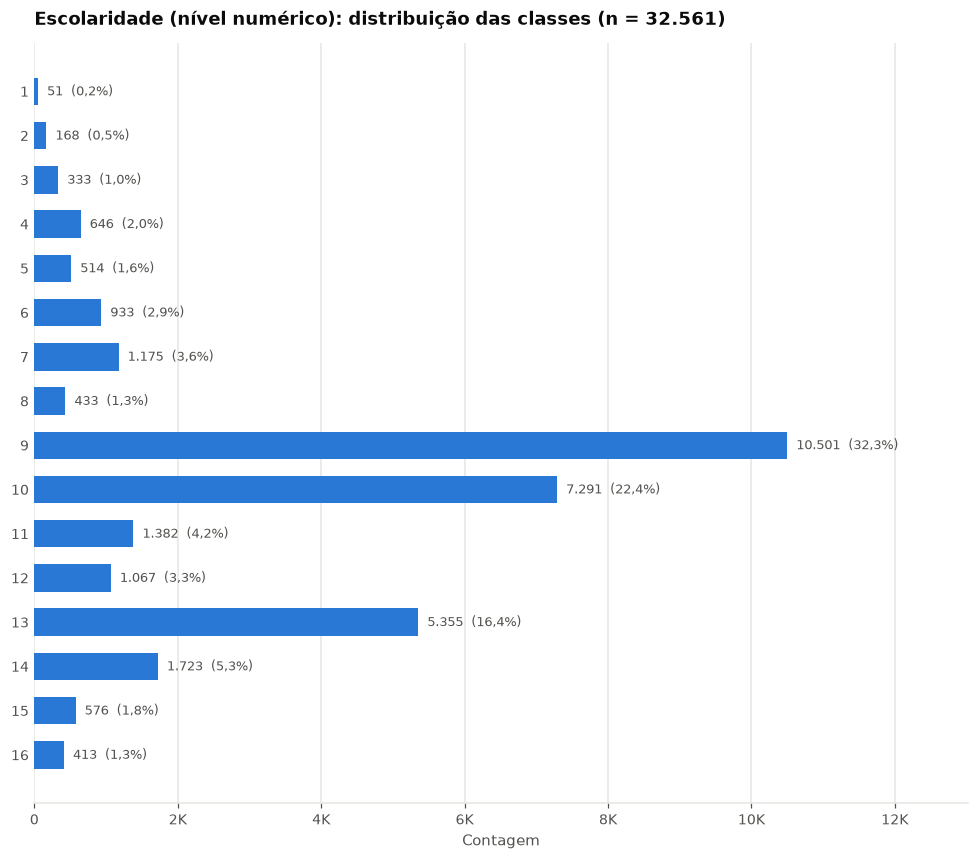

,Contagem,Percentual (%)
Classe,,
1,51,0.16
2,168,0.52
3,333,1.02
4,646,1.98
5,514,1.58
6,933,2.87
7,1175,3.61
8,433,1.33
9,10501,32.25


In [17]:
tab_escolaridade_num = distribuicao_categorica(df, "escolaridade_num", ordem=list(range(1, 17)))

In [18]:
correspondencia = (
    df.groupby("escolaridade_num")["escolaridade"]
      .agg(lambda s: " | ".join(sorted(s.unique())))
      .to_frame("Escolaridade")
)
correspondencia.index.name = "Escolaridade (nível numérico)"
correspondencia

,Escolaridade
Escolaridade (nível numérico),
1,Pré-escola
2,1ª a 4ª série
3,5ª a 6ª série
4,7ª a 8ª série
5,9ª série
6,10ª série
7,11ª série
8,12ª série
9,Ensino médio completo


### 6.5 Estado civil e relação familiar

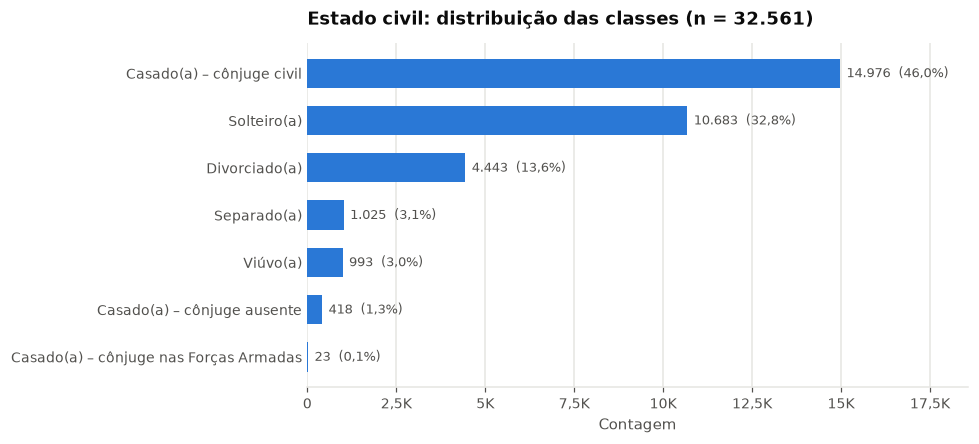

,Contagem,Percentual (%)
Classe,,
Casado(a) – cônjuge civil,14976,45.99
Solteiro(a),10683,32.81
Divorciado(a),4443,13.65
Separado(a),1025,3.15
Viúvo(a),993,3.05
Casado(a) – cônjuge ausente,418,1.28
Casado(a) – cônjuge nas Forças Armadas,23,0.07


In [19]:
tab_estado_civil = distribuicao_categorica(df, "estado_civil")

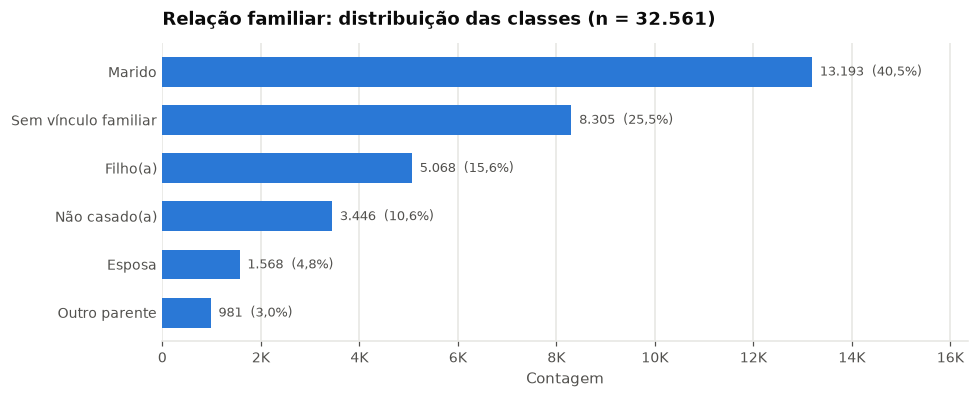

,Contagem,Percentual (%)
Classe,,
Marido,13193,40.52
Sem vínculo familiar,8305,25.51
Filho(a),5068,15.56
Não casado(a),3446,10.58
Esposa,1568,4.82
Outro parente,981,3.01


In [20]:
tab_relacao_familiar = distribuicao_categorica(df, "relacao_familiar")

### 6.6 Ocupação

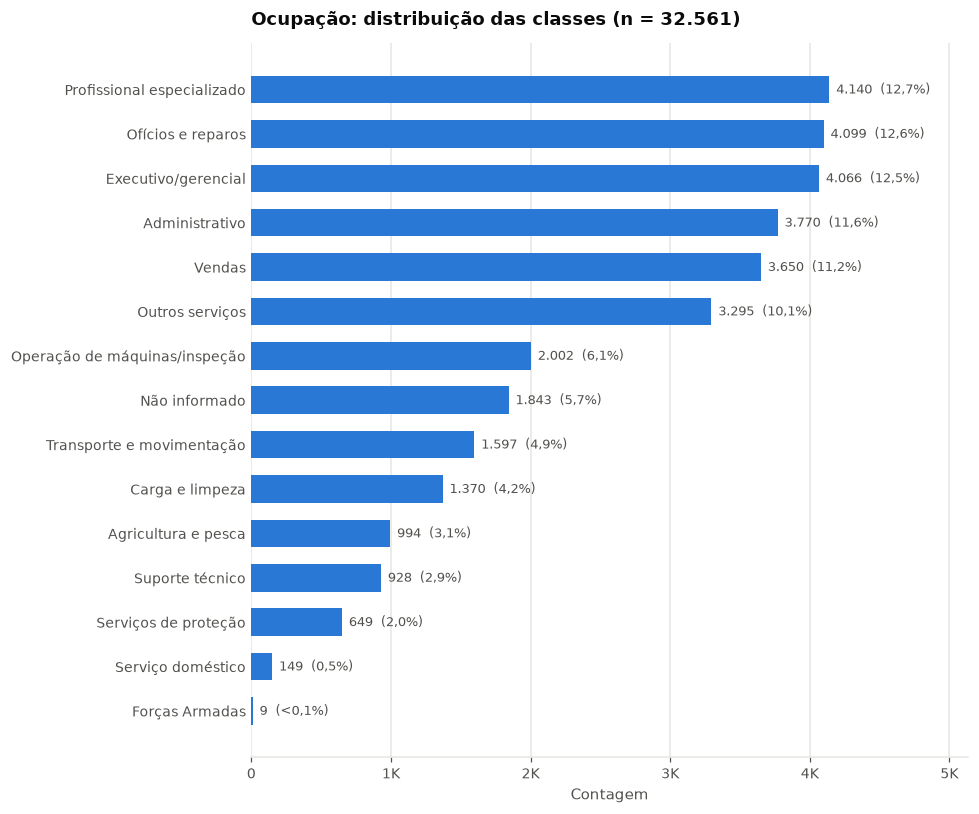

,Contagem,Percentual (%)
Classe,,
Profissional especializado,4140,12.71
Ofícios e reparos,4099,12.59
Executivo/gerencial,4066,12.49
Administrativo,3770,11.58
Vendas,3650,11.21
Outros serviços,3295,10.12
Operação de máquinas/inspeção,2002,6.15
Não informado,1843,5.66
Transporte e movimentação,1597,4.90


In [21]:
tab_ocupacao = distribuicao_categorica(df, "ocupacao")

### 6.7 País de origem

São 41 países mais o marcador de ausente. O gráfico mostra as 20 classes mais frequentes e agrupa o restante em "Outros"; a tabela traz todas. Como os Estados Unidos concentram quase 90% das linhas, um segundo gráfico mostra a distribuição **sem** os Estados Unidos para que os demais países fiquem legíveis.

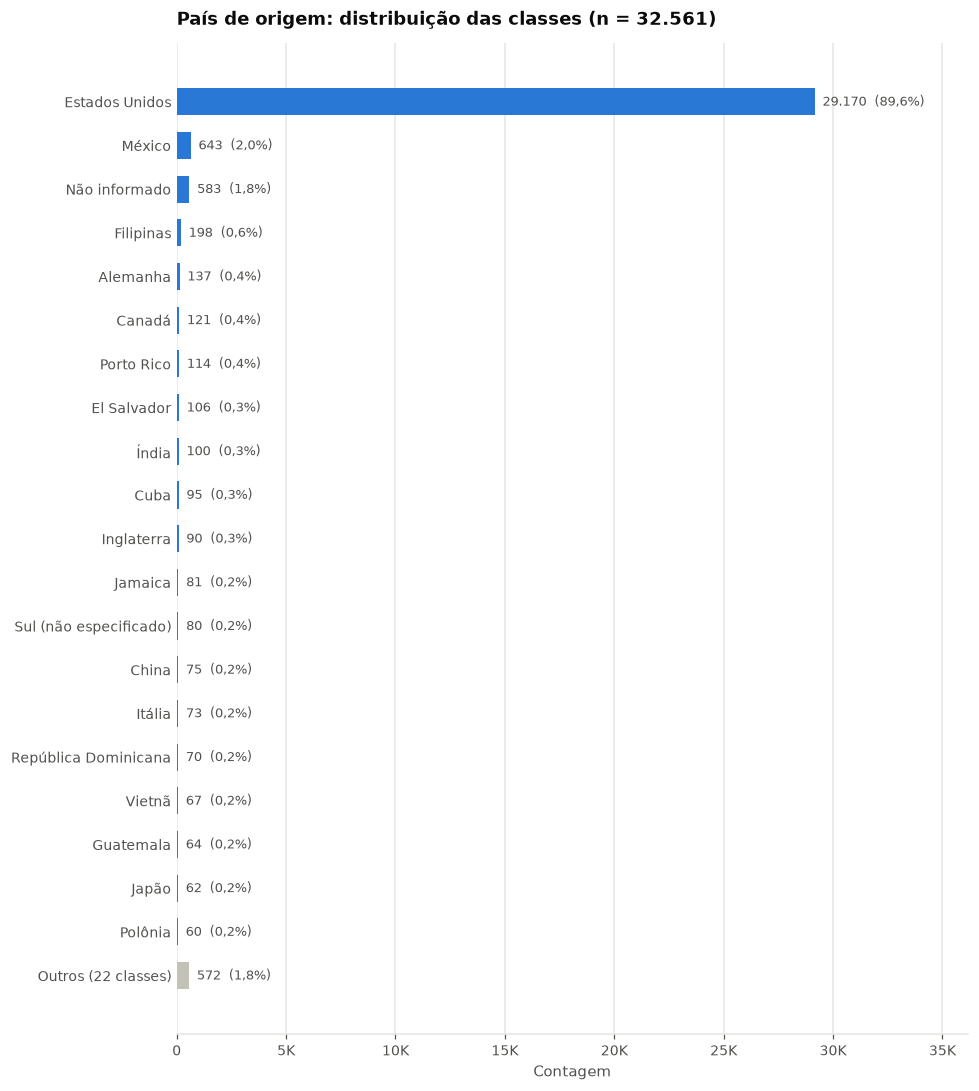

,Contagem,Percentual (%)
Classe,,
Estados Unidos,29170,89.59
México,643,1.97
Não informado,583,1.79
Filipinas,198,0.61
Alemanha,137,0.42
Canadá,121,0.37
Porto Rico,114,0.35
El Salvador,106,0.33
Índia,100,0.31


In [22]:
tab_pais = distribuicao_categorica(df, "pais_origem", max_classes=20)

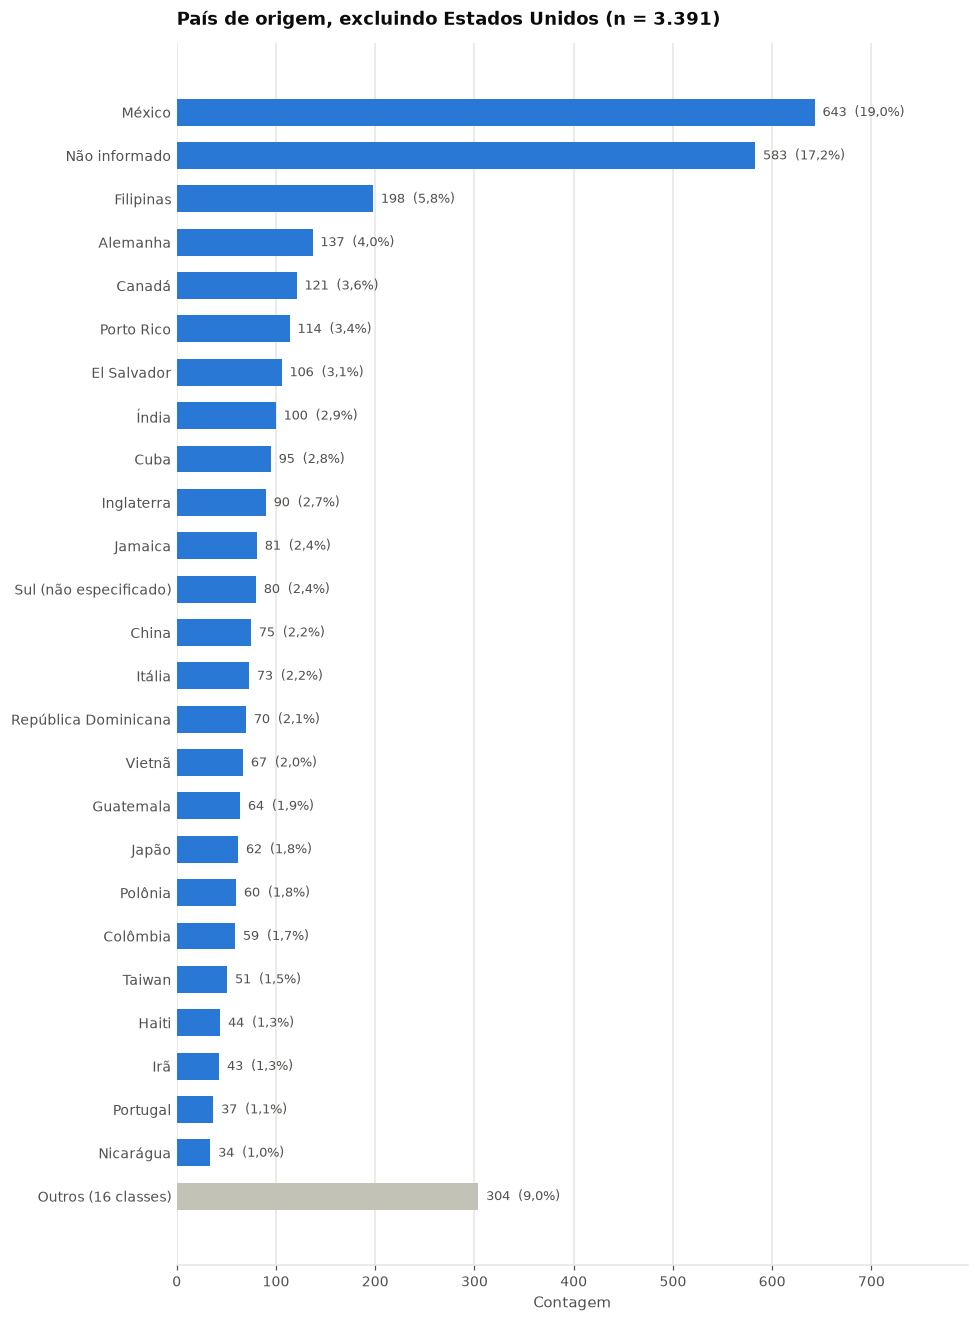

,Contagem,Percentual (%)
Classe,,
México,643,18.96
Não informado,583,17.19
Filipinas,198,5.84
Alemanha,137,4.04
Canadá,121,3.57
Porto Rico,114,3.36
El Salvador,106,3.13
Índia,100,2.95
Cuba,95,2.80


In [23]:
sem_eua = df[df["pais_origem"] != "Estados Unidos"]
tab_pais_sem_eua = distribuicao_categorica(
    sem_eua, "pais_origem", max_classes=25,
    titulo=f"País de origem, excluindo Estados Unidos (n = {formatar_int(len(sem_eua))})",
)

## 7. Distribuição das colunas numéricas

Para as colunas contínuas: histograma, resumo estatístico e tabela de contagem por faixa. As faixas da tabela são exatamente as barras do histograma: intervalos **fechados à esquerda e abertos à direita**, `[a, b)`; só a última faixa inclui o limite superior. Assim, quem trabalha exatamente 40 horas por semana cai na faixa `[40, 50)`, e não em `[30, 40)`. Ganho e perda de capital são zero para a grande maioria das pessoas, então primeiro se mostra a proporção zero vs. maior que zero e depois o histograma apenas dos valores positivos.

### 7.1 Idade

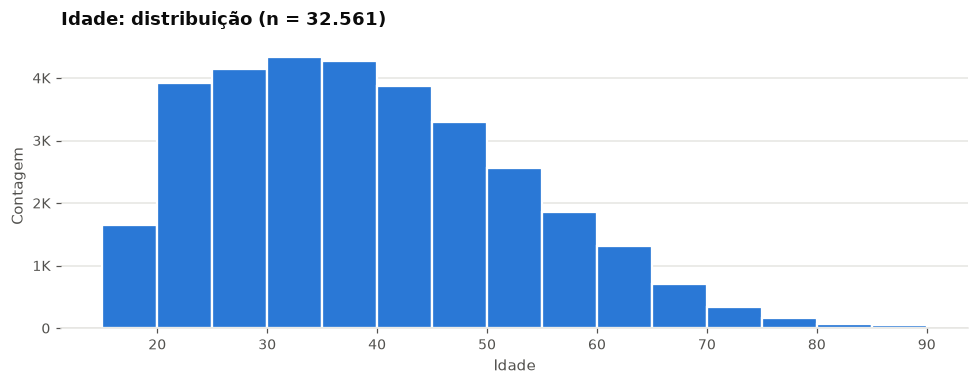

,n,média,desvio padrão,mínimo,Q1 (25%),mediana,Q3 (75%),máximo
Idade,32561.0,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0


,Contagem,Percentual (%)
Faixa,,
"[15, 20)",1657,5.09
"[20, 25)",3913,12.02
"[25, 30)",4141,12.72
"[30, 35)",4338,13.32
"[35, 40)",4275,13.13
"[40, 45)",3876,11.90
"[45, 50)",3299,10.13
"[50, 55)",2554,7.84
"[55, 60)",1864,5.72


In [24]:
tab_idade = distribuicao_numerica(df, "idade", bins=range(15, 95, 5))

### 7.2 Horas por semana

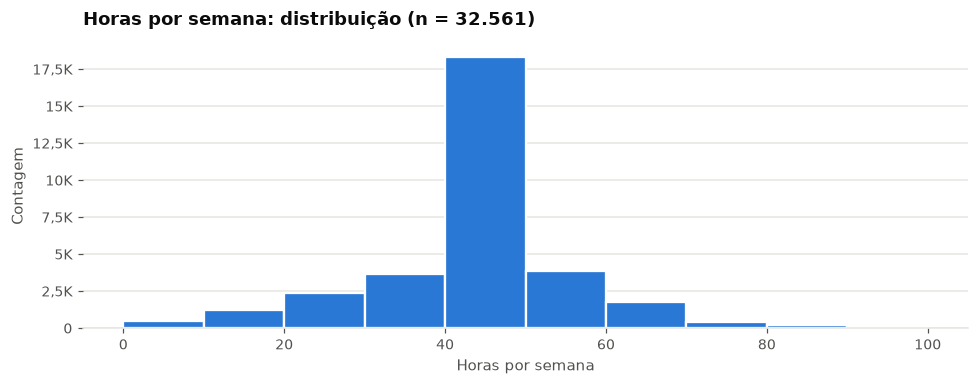

,n,média,desvio padrão,mínimo,Q1 (25%),mediana,Q3 (75%),máximo
Horas por semana,32561.0,40.437456,12.347429,1.0,40.0,40.0,45.0,99.0


,Contagem,Percentual (%)
Faixa,,
"[0, 10)",458,1.41
"[10, 20)",1246,3.83
"[20, 30)",2392,7.35
"[30, 40)",3667,11.26
"[40, 50)",18336,56.31
"[50, 60)",3877,11.91
"[60, 70)",1796,5.52
"[70, 80)",448,1.38
"[80, 90)",202,0.62


In [25]:
tab_horas = distribuicao_numerica(df, "horas_semana", bins=range(0, 101, 10))

### 7.3 Peso amostral

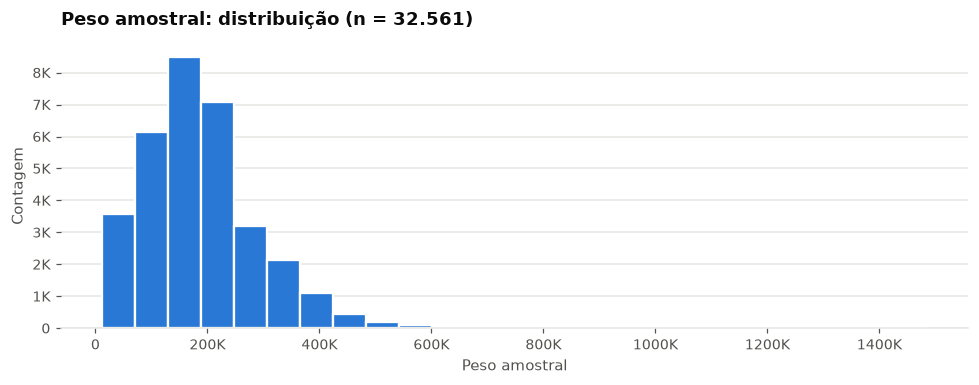

,n,média,desvio padrão,mínimo,Q1 (25%),mediana,Q3 (75%),máximo
Peso amostral,32561.0,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0


,Contagem,Percentual (%)
Faixa,,
"[12.285, 71.181)",3560,10.93
"[71.181, 130.078)",6128,18.82
"[130.078, 188.975)",8494,26.09
"[188.975, 247.872)",7074,21.73
"[247.872, 306.769)",3188,9.79
"[306.769, 365.665)",2138,6.57
"[365.665, 424.562)",1109,3.41
"[424.562, 483.459)",430,1.32
"[483.459, 542.356)",189,0.58


In [26]:
tab_peso = distribuicao_numerica(df, "peso_amostral", bins=25)

### 7.4 Ganho e perda de capital

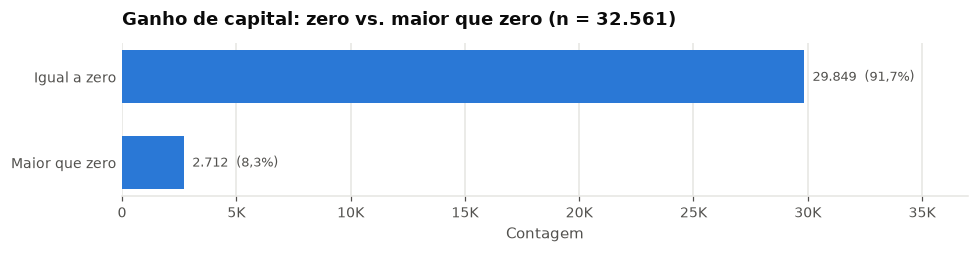

,Contagem,Percentual (%)
Classe,,
Igual a zero,29849,91.67
Maior que zero,2712,8.33


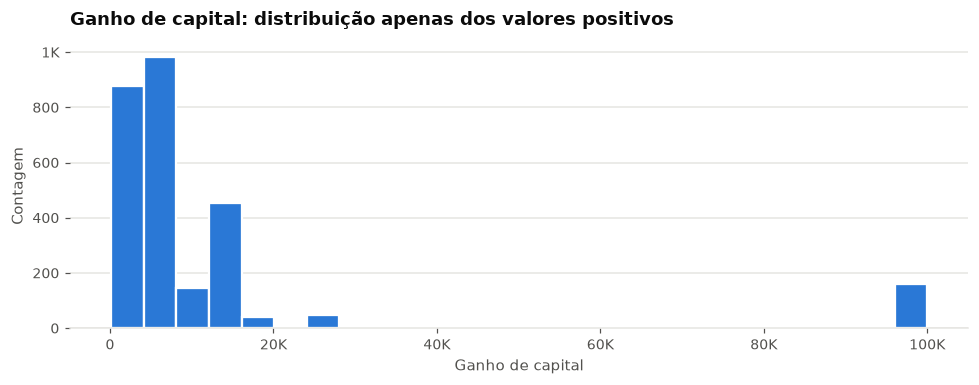

,n,média,desvio padrão,mínimo,Q1 (25%),mediana,Q3 (75%),máximo
Ganho de capital (apenas valores > 0),2712.0,12938.541298,22395.41353,114.0,3411.0,7298.0,14084.0,99999.0


,Contagem,Percentual (%)
Faixa,,
"[114, 4.109)",878,32.37
"[4.109, 8.104)",983,36.25
"[8.104, 12.100)",144,5.31
"[12.100, 16.095)",452,16.67
"[16.095, 20.091)",39,1.44
"[20.091, 24.086)",1,0.04
"[24.086, 28.081)",49,1.81
"[28.081, 32.077)",0,0.00
"[32.077, 36.072)",5,0.18


In [27]:
def zero_vs_positivo(df, coluna):
    classes = pd.Series(np.where(df[coluna] > 0, "Maior que zero", "Igual a zero"), name=coluna)
    return distribuicao_categorica(classes.to_frame(), coluna, ordem=["Igual a zero", "Maior que zero"],
                                   titulo=f"{rotulo(coluna)}: zero vs. maior que zero (n = {formatar_int(len(df))})")

tab_ganho_zero = zero_vs_positivo(df, "ganho_capital")
tab_ganho = distribuicao_numerica(df, "ganho_capital", bins=25, somente_positivos=True,
                                  titulo="Ganho de capital: distribuição apenas dos valores positivos")

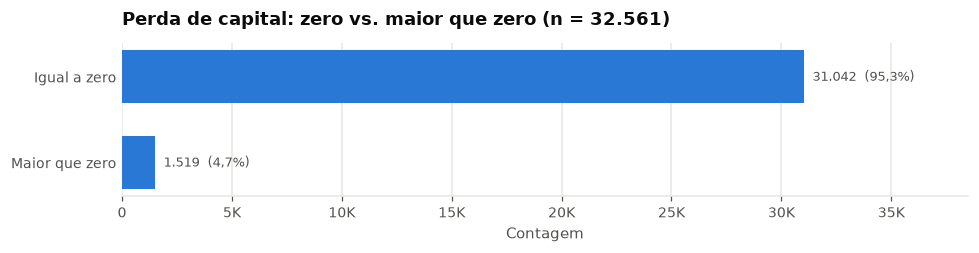

,Contagem,Percentual (%)
Classe,,
Igual a zero,31042,95.33
Maior que zero,1519,4.67


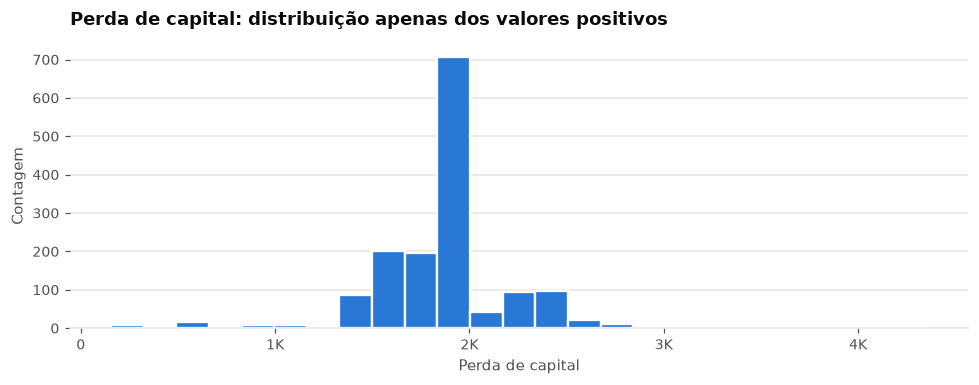

,n,média,desvio padrão,mínimo,Q1 (25%),mediana,Q3 (75%),máximo
Perda de capital (apenas valores > 0),1519.0,1871.428571,376.571535,155.0,1672.0,1887.0,1977.0,4356.0


,Contagem,Percentual (%)
Faixa,,
"[155, 323)",8,0.53
"[323, 491)",3,0.20
"[491, 659)",15,0.99
"[659, 827)",2,0.13
"[827, 995)",8,0.53
"[995, 1.163)",9,0.59
"[1.163, 1.331)",4,0.26
"[1.331, 1.499)",87,5.73
"[1.499, 1.667)",200,13.17


In [28]:
tab_perda_zero = zero_vs_positivo(df, "perda_capital")
tab_perda = distribuicao_numerica(df, "perda_capital", bins=25, somente_positivos=True,
                                  titulo="Perda de capital: distribuição apenas dos valores positivos")

## 8. Observações iniciais

- **Alvo desbalanceado:** cerca de 76% das pessoas ganham até US$ 50 mil e 24% ganham mais. Métricas como acurácia precisam ser lidas com cuidado; vale usar precisão, revocação, F1 ou AUC.
- **Amostra concentrada:** cerca de 67% homens, 85% brancos e 90% nascidos nos Estados Unidos. Várias classes são raras (Nunca trabalhou, Sem remuneração, Forças Armadas, Casado(a) com cônjuge nas Forças Armadas, Holanda com uma única linha), o que afeta codificação e validação cruzada.
- **Ausentes:** só em classe de trabalho (5,6%), ocupação (5,7%) e país de origem (1,8%). Todas as 1.836 linhas sem classe de trabalho também estão sem ocupação; as 7 linhas restantes sem ocupação são exatamente as de quem nunca trabalhou, ou seja, ali o "ausente" é na verdade "não se aplica".
- **Duplicatas:** há 24 linhas idênticas em todas as colunas; vale decidir se serão removidas antes da modelagem.
- **Escolaridade:** ensino médio completo, superior incompleto e bacharelado respondem por cerca de 70% das linhas; `escolaridade_num` é um mapeamento 1:1 de `escolaridade`, então uma das duas é redundante.
- **Ganho e perda de capital:** mais de 90% de zeros, com cauda longa (159 linhas têm ganho de capital exatamente igual a 99.999, o que parece ser um teto de codificação).
- **Horas por semana:** forte concentração em 40 horas, valor exato de 47% das pessoas.
- **Peso amostral:** não descreve a pessoa; deve ser descartado como atributo preditivo ou usado apenas como peso.

**Próximos passos:** cruzar cada atributo com a variável alvo, decidir o tratamento dos ausentes e das classes raras, e definir a codificação das variáveis categóricas para a modelagem.